<a href="https://colab.research.google.com/github/zohaibahmedshaikh32-coder/Machine_Learning_labs/blob/main/MlLab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Task 1: Load Dataset
import pandas as pd
from sklearn.datasets import load_breast_cancer

# Load the Breast Cancer Wisconsin Dataset
raw_data = load_breast_cancer()

# Convert to Pandas DataFrame for data inspection
df = pd.DataFrame(data=raw_data.data, columns=raw_data.feature_names)
df['target'] = raw_data.target

# Target map: 0 -> Malignant, 1 -> Benign
target_names = raw_data.target_names

print(f"Dataset Shape: {df.shape}")
print("\nFirst 5 rows of the dataset:")
df.head()

Dataset Shape: (569, 31)

First 5 rows of the dataset:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [ ]:
# Task 2: Data Preprocessing
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Check for Missing Values
print("Total missing values:", df.isnull().sum().sum())

# 2. Separate Features (X) and Target (y)
X = df.drop(columns=['target'])
y = df['target']

# 3. Standardize Feature Scales
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nData preprocessing completed successfully.")
print(f"Features shape: {X_scaled.shape}")
print(f"Target distribution:\n{y.value_counts()}")

Total missing values: 0

Data preprocessing completed successfully.
Features shape: (569, 30)
Target distribution:
target
1    357
0    212
Name: count, dtype: int64


In [ ]:
# Task 3: Train-Test Split
from sklearn.model_selection import train_test_split

# Split data into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training sample count: {X_train.shape[0]}")
print(f"Testing sample count:  {X_test.shape[0]}")

Training sample count: 455
Testing sample count:  114


In [ ]:
# Task 4: Train Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,       # Number of decision trees
    max_features='sqrt',    # Feature randomness at each split
    bootstrap=True,         # Bootstrap aggregating (Bagging)
    random_state=42
)

# Fit model to training data
rf_model.fit(X_train, y_train)

print("Random Forest Classifier trained successfully.")

Random Forest Classifier trained successfully.


In [ ]:
# Task 5: Make Predictions
import pandas as pd

y_pred_rf = rf_model.predict(X_test)

# Display sample predictions vs actual targets
results_df = pd.DataFrame({
    'Actual': [target_names[i] for i in y_test[:10]],
    'Predicted': [target_names[i] for i in y_pred_rf[:10]]
})
print("Sample Predictions (First 10 Test Instances):")
print(results_df)

Sample Predictions (First 10 Test Instances):
      Actual  Predicted
0  malignant  malignant
1     benign     benign
2  malignant  malignant
3     benign  malignant
4  malignant  malignant
5     benign     benign
6     benign     benign
7  malignant  malignant
8  malignant  malignant
9  malignant  malignant


In [ ]:
# Task 6: Model Performance Evaluation
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)

print("--- Random Forest Performance Metrics ---")
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-Score:  {rf_f1:.4f}")

print("\nFull Classification Report:")
print(classification_report(y_test, y_pred_rf, target_names=target_names))

--- Random Forest Performance Metrics ---
Accuracy:  0.9561
Precision: 0.9589
Recall:    0.9722
F1-Score:  0.9655

Full Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



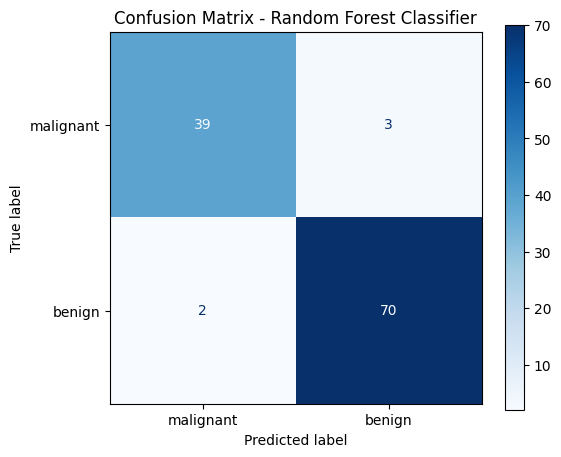

In [ ]:
# Task 7: Confusion Matrix Visualization
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(cmap='Blues', ax=ax, colorbar=True)

plt.title('Confusion Matrix - Random Forest Classifier')
plt.grid(False)
plt.show()

--- Performance Comparison ---
   Metric  Single Decision Tree  Random Forest
 Accuracy              0.912281       0.956140
Precision              0.955882       0.958904
   Recall              0.902778       0.972222
 F1-Score              0.928571       0.965517


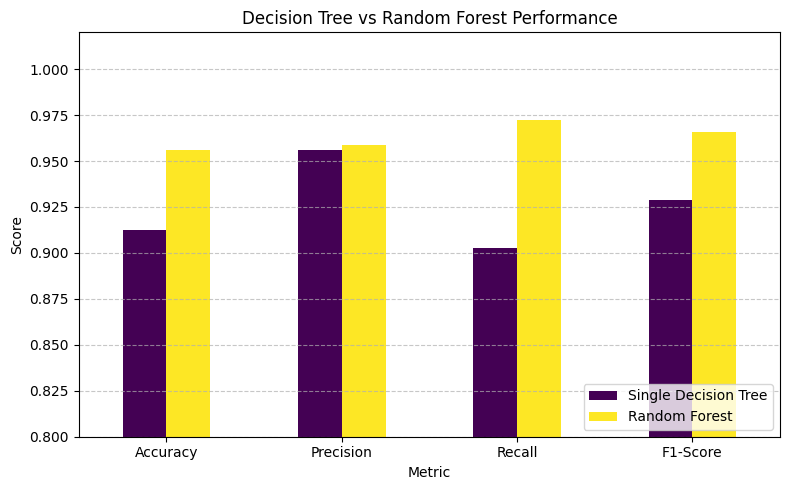

In [ ]:
# Task 8: Model Comparison (Single Decision Tree vs Random Forest)
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Train a Single Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

# 2. Compute Metrics for Decision Tree
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt)
dt_recall = recall_score(y_test, y_pred_dt)
dt_f1 = f1_score(y_test, y_pred_dt)

# 3. Build Comparison Table
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Single Decision Tree': [dt_accuracy, dt_precision, dt_recall, dt_f1],
    'Random Forest': [rf_accuracy, rf_precision, rf_recall, rf_f1]
})

print("--- Performance Comparison ---")
print(comparison_df.to_string(index=False))

# 4. Visualization of Metric Comparison
comparison_df.set_index('Metric').plot(kind='bar', figsize=(8, 5), colormap='viridis')
plt.title('Decision Tree vs Random Forest Performance')
plt.ylabel('Score')
plt.ylim(0.8, 1.02)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()